# 07 — `matplotlib` & `seaborn` (Visualisasi Probabilitas dan Distribusi)
**Mata Kuliah:** Probabilitas dan Statistika | **Nama / NIM:** ________

Visualisasi membuat konsep probabilitas terlihat: konvergensi simulasi, pohon peluang, diagram Venn, bentuk distribusi, ekor berat, dan kecocokan model (Q–Q plot). Data dibangkitkan dengan NumPy/SciPy; fokus notebook ini adalah **cara memvisualisasikan**.

## 1. Eksplorasi Library
| Library | Fungsi utama | Kegunaan |
|---|---|---|
| `matplotlib.pyplot` | `subplots`, `bar`, `stem`, `step`, `plot`, `hist`, `fill_between`, `scatter`, `imshow`, `boxplot`, `annotate`, `eventplot` | Grafik dasar PMF, PDF, CDF, histogram, anotasi |
| `matplotlib.patches` | `Circle`, `FancyArrowPatch` | Diagram Venn & pohon peluang |
| `seaborn` | `histplot(kde=True)`, `kdeplot`, `ecdfplot`, `boxplot`, `violinplot`, `heatmap`, `jointplot`, `pairplot` | Visualisasi statistik tingkat tinggi |
| `scipy.stats.probplot` | Q–Q plot | Cek kecocokan distribusi |

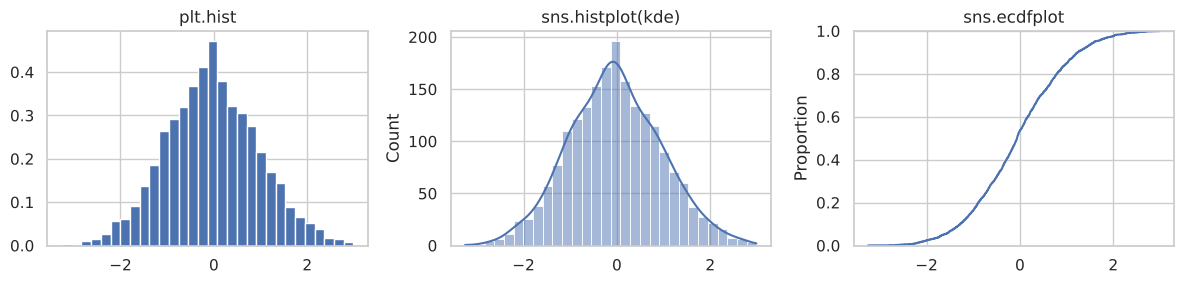

In [1]:
import numpy as np, math, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.patches import Circle
from scipy import stats
sns.set_theme(style="whitegrid")
rng=np.random.default_rng(7)

fig,ax=plt.subplots(1,3,figsize=(12,3))
x=rng.normal(0,1,2000)
ax[0].hist(x,bins=30,density=True); ax[0].set_title("plt.hist")
sns.histplot(x,kde=True,ax=ax[1]); ax[1].set_title("sns.histplot(kde)")
sns.ecdfplot(x,ax=ax[2]); ax[2].set_title("sns.ecdfplot"); plt.tight_layout(); plt.show()

## 2. Implementasi pada Permasalahan Probabilitas
### Soal 2.1 — Diagram Venn: inklusi–eksklusi
Dari 100 mahasiswa: 33 menguasai Python (kelipatan 3), 20 Java (kelipatan 5), 6 keduanya. Gambarkan Venn dan hitung P(Python ∪ Java)=0,47.

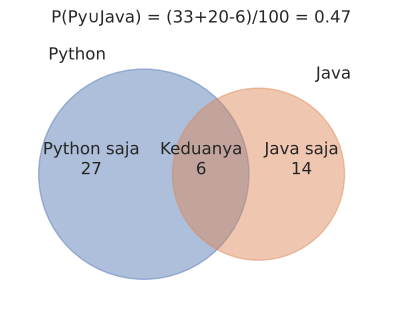

In [2]:
py,jv,both=33,20,6
fig,ax=plt.subplots(figsize=(6,3.6))
ax.add_patch(Circle((-.6,0),1.1,alpha=.45,color="C0")); ax.add_patch(Circle((.6,0),.9,alpha=.45,color="C1"))
ax.text(-1.15,0,f"Python saja\n{py-both}",ha="center"); ax.text(1.05,0,f"Java saja\n{jv-both}",ha="center"); ax.text(0,0,f"Keduanya\n{both}",ha="center")
ax.text(-1.6,1.2,"Python"); ax.text(1.2,1.0,"Java")
ax.set_xlim(-2,2); ax.set_ylim(-1.4,1.5); ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"P(Py∪Java) = ({py}+{jv}-{both})/100 = {(py+jv-both)/100}"); plt.show()

**Interpretasi:** Venn memperlihatkan mengapa irisan harus dikurangkan: 6 mahasiswa terhitung dua kali bila hanya menjumlah 33+20. Peluang gabungan 0,47.

### Soal 2.2 — Pohon peluang (Bayes pada IDS)
Prior serangan 1%, TPR 99%, FPR 5%. Gambar pohon dan tandai cabang yang menghasilkan alarm: P(serangan|alarm) = 0,0099/(0,0099+0,0495)=1/6.

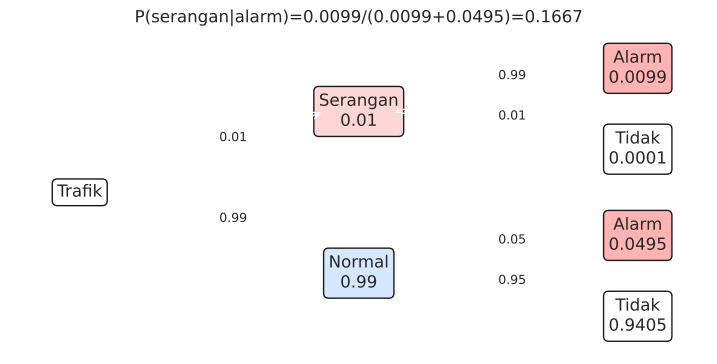

In [3]:
fig,ax=plt.subplots(figsize=(9,4.2)); ax.axis("off"); ax.set_xlim(0,10); ax.set_ylim(0,6)
def node(x,y,t,c="white"): ax.text(x,y,t,ha="center",va="center",bbox=dict(boxstyle="round",fc=c,ec="k"))
def edge(x1,y1,x2,y2,t): ax.annotate("",(x2-.5,y2),(x1+.5,y1),arrowprops=dict(arrowstyle="->")); ax.text((x1+x2)/2,(y1+y2)/2+.2,t,fontsize=9)
node(1,3,"Trafik"); node(5,4.5,"Serangan\n0.01","#ffd6d6"); node(5,1.5,"Normal\n0.99","#d6e8ff")
edge(1,3,5,4.5,"0.01"); edge(1,3,5,1.5,"0.99")
node(9,5.3,"Alarm\n0.0099","#ffb3b3"); node(9,3.8,"Tidak\n0.0001"); node(9,2.2,"Alarm\n0.0495","#ffb3b3"); node(9,.7,"Tidak\n0.9405")
edge(5,4.5,9,5.3,"0.99"); edge(5,4.5,9,3.8,"0.01"); edge(5,1.5,9,2.2,"0.05"); edge(5,1.5,9,.7,"0.95")
ax.set_title("P(serangan|alarm)=0.0099/(0.0099+0.0495)=%.4f"%(0.0099/(0.0099+0.0495))); plt.show()

**Interpretasi:** Dua cabang berwarna merah muda adalah semua jalur yang berujung alarm; hanya 0,0099 dari total 0,0594 berasal dari serangan nyata (±16,7%). Pohon peluang mengubah rumus Bayes menjadi perkalian sepanjang cabang dan penjumlahan antar-cabang.

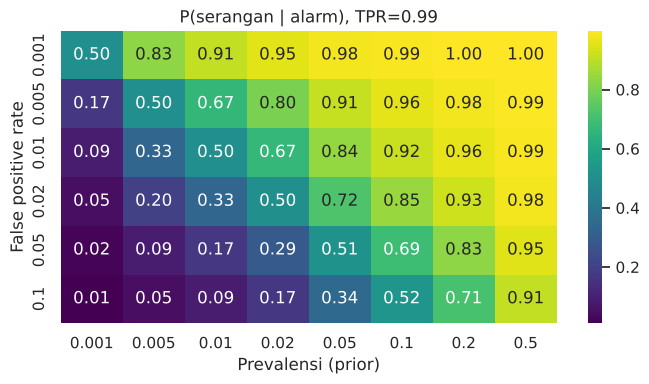

In [4]:
# Heatmap: posterior sebagai fungsi prevalensi dan false-positive-rate (TPR=0.99)
prev=np.array([.001,.005,.01,.02,.05,.1,.2,.5]); fpr=np.array([.001,.005,.01,.02,.05,.1])
post=np.array([[pv*.99/(pv*.99+(1-pv)*f) for pv in prev] for f in fpr])
plt.figure(figsize=(8,3.8)); sns.heatmap(post,annot=True,fmt=".2f",cmap="viridis",xticklabels=prev,yticklabels=fpr)
plt.xlabel("Prevalensi (prior)"); plt.ylabel("False positive rate"); plt.title("P(serangan | alarm), TPR=0.99"); plt.show()

**Interpretasi:** Kolom kiri (prevalensi rendah) menunjukkan posterior kecil walau FPR rendah; peluang yang bermakna baru muncul bila prevalensi tinggi atau FPR sangat kecil. Memperbaiki FPR dari 5% ke 0,5% (baris) mengubah posterior pada prior 1% dari 0,17 menjadi 0,67.

### Soal 2.3 — Konvergensi Monte Carlo & pita galat 1/√N
Estimasi P(sum dua dadu = 8) = 5/36 dari 30 lintasan independen; bandingkan dengan pita ±2√(p(1−p)/n).

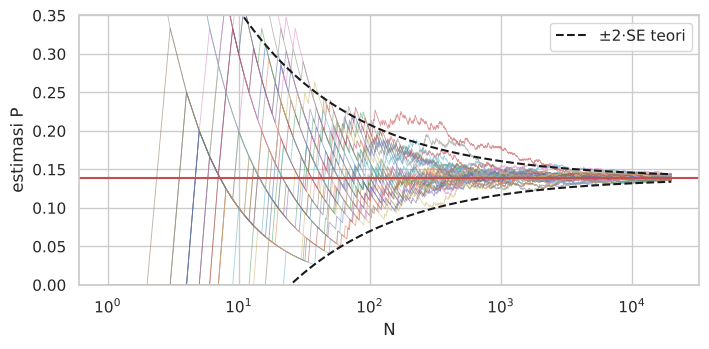

sd antar-lintasan pada N=20000: 0.00263  | SE teori: 0.00245


In [5]:
p=5/36; n=np.arange(1,20_001)
runs=[np.cumsum((rng.integers(1,7,n.size)+rng.integers(1,7,n.size))==8)/n for _ in range(30)]
fig,ax=plt.subplots(figsize=(8,3.5))
for r in runs: ax.plot(n,r,lw=.6,alpha=.6)
band=2*np.sqrt(p*(1-p)/n); ax.plot(n,p+band,'k--'); ax.plot(n,p-band,'k--',label="±2·SE teori"); ax.axhline(p,c='r')
ax.set_xscale("log"); ax.set_ylim(0,.35); ax.set_xlabel("N"); ax.set_ylabel("estimasi P"); ax.legend(); plt.show()
finals=np.array([r[-1] for r in runs]); print("sd antar-lintasan pada N=20000:",finals.std().round(5)," | SE teori:",round(math.sqrt(p*(1-p)/20000),5))

**Interpretasi:** 30 lintasan melebar di awal lalu menyempit mengikuti corong ±2/√N; simpangan baku antar-lintasan pada N=20.000 mendekati galat baku teori (≈0,0024). Untuk mengurangi galat setengahnya diperlukan 4× lebih banyak sampel.

### Soal 2.4 — Distribusi gabungan dua dadu: heatmap sum & max
Gambarkan peluang gabungan (X=jumlah, Y=maks) dari dua dadu dan marginalnya.

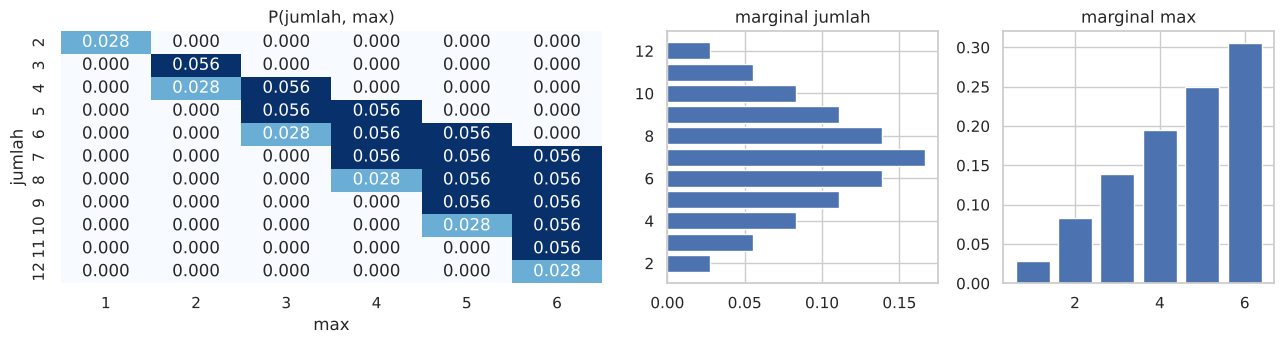

Total = 1.0  | P(jumlah=8 | max=5) = 0.2222 (manual: (3,5),(5,3) dari 9 kasus = 2/9 = 0.2222 )


In [6]:
J=np.zeros((11,6))
for a in range(1,7):
    for b in range(1,7): J[a+b-2,max(a,b)-1]+=1/36
fig,ax=plt.subplots(1,3,figsize=(13,3.6),gridspec_kw={"width_ratios":[2,1,1]})
sns.heatmap(J,annot=True,fmt=".3f",cmap="Blues",xticklabels=range(1,7),yticklabels=range(2,13),ax=ax[0],cbar=False); ax[0].set_xlabel("max"); ax[0].set_ylabel("jumlah"); ax[0].set_title("P(jumlah, max)")
ax[1].barh(range(2,13),J.sum(1)); ax[1].set_title("marginal jumlah"); ax[2].bar(range(1,7),J.sum(0)); ax[2].set_title("marginal max"); plt.tight_layout(); plt.show()
print("Total =",J.sum().round(4)," | P(jumlah=8 | max=5) =",(J[6,4]/J[:,4].sum()).round(4),"(manual: (3,5),(5,3) dari 9 kasus = 2/9 =",round(2/9,4),")")

**Interpretasi:** Banyak sel bernilai 0 (mis. max=1 hanya bisa jumlah 2) sehingga X dan Y **tidak independen**. Peluang bersyarat didapat dengan menormalkan satu kolom: P(8|max=5)=2/9.

## 3. Implementasi pada Distribusi Probabilitas
### Soal 3.1 — Galeri distribusi diskrit (PMF dengan `stem`/`bar`)

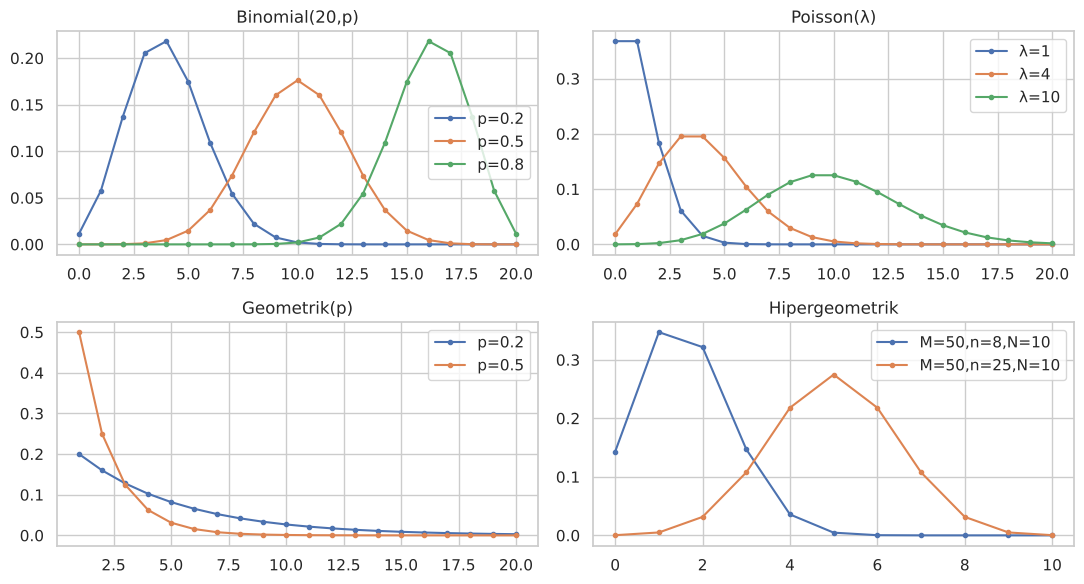

In [7]:
fig,ax=plt.subplots(2,2,figsize=(11,6))
k=np.arange(0,21)
for pp in (.2,.5,.8): ax[0,0].plot(k,stats.binom(20,pp).pmf(k),'o-',ms=3,label=f"p={pp}")
ax[0,0].set_title("Binomial(20,p)"); ax[0,0].legend()
for lam in (1,4,10): ax[0,1].plot(k,stats.poisson(lam).pmf(k),'o-',ms=3,label=f"λ={lam}")
ax[0,1].set_title("Poisson(λ)"); ax[0,1].legend()
for pp in (.2,.5): ax[1,0].plot(k[1:],stats.geom(pp).pmf(k[1:]),'o-',ms=3,label=f"p={pp}")
ax[1,0].set_title("Geometrik(p)"); ax[1,0].legend()
for (M,n,N) in ((50,8,10),(50,25,10)): ax[1,1].plot(k[:11],stats.hypergeom(M,n,N).pmf(k[:11]),'o-',ms=3,label=f"M={M},n={n},N={N}")
ax[1,1].set_title("Hipergeometrik"); ax[1,1].legend(); plt.tight_layout(); plt.show()

**Interpretasi:** Binomial simetris pada p=0,5 dan miring pada p yang ekstrem; Poisson makin simetris dan lebar seiring λ; Geometrik monoton turun (kemungkinan sukses cepat paling besar); Hipergeometrik bergeser sesuai proporsi sukses di populasi.

### Soal 3.2 — Galeri distribusi kontinu: PDF dan CDF berdampingan

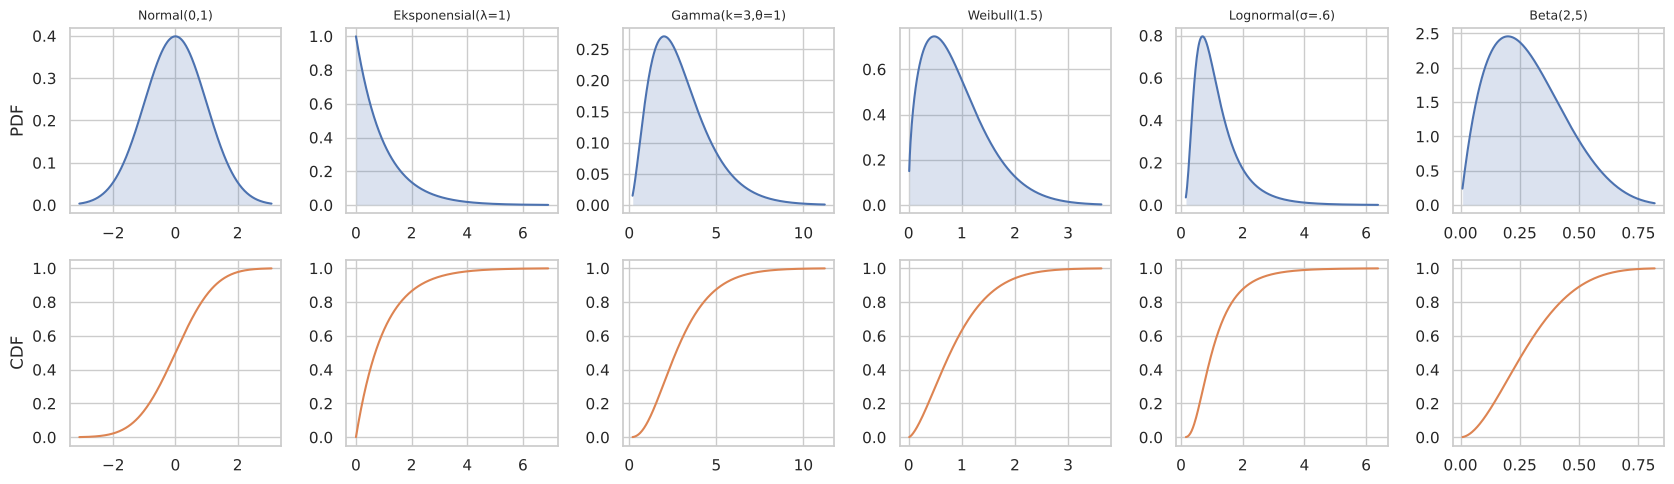

In [8]:
D={"Normal(0,1)":stats.norm(0,1),"Eksponensial(λ=1)":stats.expon(),"Gamma(k=3,θ=1)":stats.gamma(3),
   "Weibull(1.5)":stats.weibull_min(1.5),"Lognormal(σ=.6)":stats.lognorm(.6),"Beta(2,5)":stats.beta(2,5)}
fig,ax=plt.subplots(2,6,figsize=(17,5))
for i,(nm,d) in enumerate(D.items()):
    lo,hi=d.ppf(.001),d.ppf(.999); x=np.linspace(lo,hi,300)
    ax[0,i].plot(x,d.pdf(x)); ax[0,i].fill_between(x,d.pdf(x),alpha=.2); ax[0,i].set_title(nm,fontsize=9)
    ax[1,i].plot(x,d.cdf(x),c="C1")
ax[0,0].set_ylabel("PDF"); ax[1,0].set_ylabel("CDF"); plt.tight_layout(); plt.show()

**Interpretasi:** Baris atas menunjukkan bentuk kepadatan (simetris, miring kanan, terbatas [0,1]); baris bawah menunjukkan CDF yang selalu naik dari 0 ke 1. Luas di bawah PDF antara a dan b sama dengan selisih CDF F(b)−F(a).

### Soal 3.3 — Probabilitas sebagai luas daerah: P(a<X<b) dan kuantil
Latensi N(200,30²): arsir P(170<X<230) dan tandai P95.

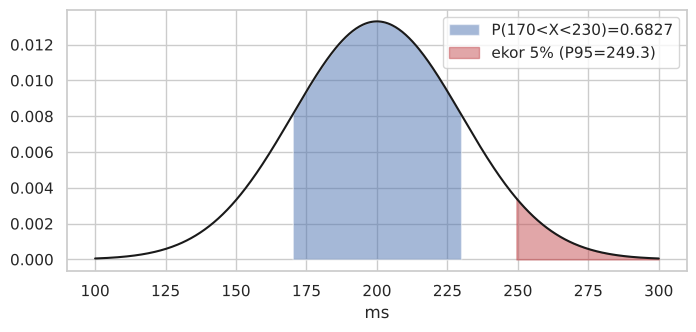

In [9]:
X=stats.norm(200,30); x=np.linspace(100,300,500)
fig,ax=plt.subplots(figsize=(8,3.4)); ax.plot(x,X.pdf(x),'k')
m=(x>=170)&(x<=230); ax.fill_between(x[m],X.pdf(x[m]),alpha=.5,label=f"P(170<X<230)={X.cdf(230)-X.cdf(170):.4f}")
t=x>=X.ppf(.95); ax.fill_between(x[t],X.pdf(x[t]),color="r",alpha=.5,label=f"ekor 5% (P95={X.ppf(.95):.1f})")
ax.legend(); ax.set_xlabel("ms"); plt.show()

**Interpretasi:** Probabilitas pada variabel kontinu = luas area, bukan tinggi kurva. Area tengah ±1σ = 0,6827; ujung kanan 5% dimulai pada ±249,3 ms (batas SLA P95).

### Soal 3.4 — Teorema Limit Pusat dengan `seaborn`
Rata-rata n sampel dari Eksponensial(1) (sangat miring) untuk n=1,2,10,50, dilapisi kurva Normal(1, 1/√n).

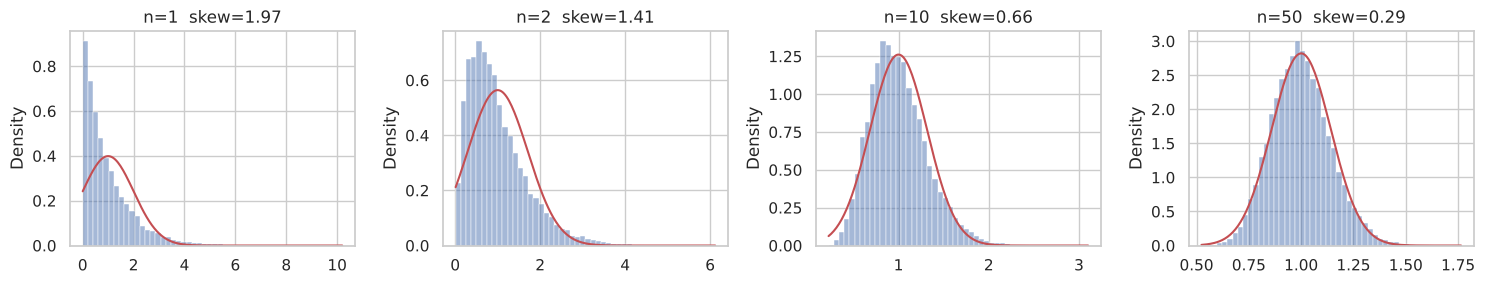

In [10]:
fig,ax=plt.subplots(1,4,figsize=(15,3))
for a,n in zip(ax,(1,2,10,50)):
    m=rng.exponential(1,(20_000,n)).mean(1)
    sns.histplot(m,stat="density",bins=50,ax=a,alpha=.5)
    xs=np.linspace(max(m.min(),0),m.max(),200); a.plot(xs,stats.norm(1,1/math.sqrt(n)).pdf(xs),'r'); a.set_title(f"n={n}  skew={stats.skew(m):.2f}")
plt.tight_layout(); plt.show()

**Interpretasi:** Skewness turun dari ≈2 (n=1) mendekati 0 (n=50, ≈0,28): skewness teori rata-rata = 2/√n. Distribusi rata-rata semakin simetris dan menempel pada kurva Normal.

### Soal 3.5 — Membandingkan distribusi: box, violin, ECDF (seaborn)
Latensi tiga layanan: A~Normal, B~Lognormal, C~Eksponensial dengan mean sama (100 ms).

{'A (Normal)': 100.0, 'B (Lognormal)': 100.7, 'C (Eksponensial)': 99.9}
{'A (Normal)': 146.1, 'B (Lognormal)': 341.7, 'C (Eksponensial)': 445.9}


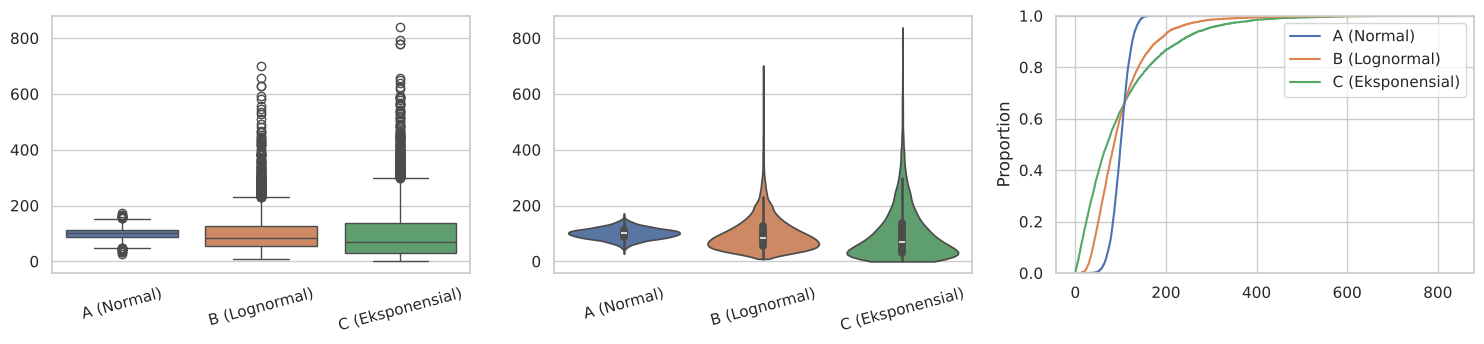

In [11]:
import pandas as pd
n=5000
df=pd.DataFrame({"A (Normal)":rng.normal(100,20,n),"B (Lognormal)":rng.lognormal(math.log(100)-.18,.6,n),"C (Eksponensial)":rng.exponential(100,n)})
print(df.mean().round(1).to_dict()); print(df.quantile(.99).round(1).to_dict())
fig,ax=plt.subplots(1,3,figsize=(15,3.6))
sns.boxplot(data=df,ax=ax[0]); ax[0].tick_params(axis='x',rotation=15)
sns.violinplot(data=df,ax=ax[1],cut=0); ax[1].tick_params(axis='x',rotation=15)
sns.ecdfplot(data=df,ax=ax[2]); plt.tight_layout(); plt.show()

**Interpretasi:** Ketiganya bermean ≈100 ms tetapi ekornya sangat berbeda: persentil ke-99 layanan C ±446 ms, B ±342 ms, vs A ±146 ms. Rata-rata saja menyembunyikan risiko ekor — gunakan persentil, boxplot, dan ECDF.

### Soal 3.6 — Q–Q plot: apakah data Normal?
Bandingkan Q–Q plot terhadap Normal untuk data Normal, Lognormal, dan Eksponensial; deteksi penyimpangan dari garis lurus.

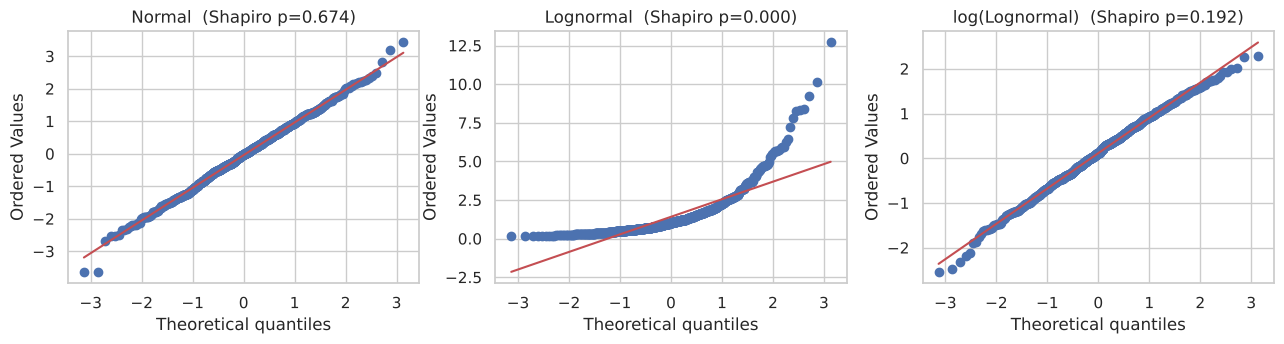

In [12]:
fig,ax=plt.subplots(1,3,figsize=(13,3.6))
for a,(nm,d) in zip(ax,[("Normal",rng.normal(0,1,800)),("Lognormal",rng.lognormal(0,.8,800)),("log(Lognormal)",np.log(rng.lognormal(0,.8,800)))]):
    stats.probplot(d,dist="norm",plot=a); a.set_title(nm+f"  (Shapiro p={stats.shapiro(d).pvalue:.3f})")
plt.tight_layout(); plt.show()

**Interpretasi:** Titik data Normal menempel pada garis; Lognormal melengkung tajam di ekor atas (miring kanan), tetapi setelah transformasi log kembali lurus. Shapiro–Wilk mengonfirmasi (p kecil = tolak normalitas).

### Soal 3.7 — Normal bivariat: kontur dan `jointplot`
(Latensi, ukuran paket) dengan korelasi ρ=0, 0,6, −0,8.

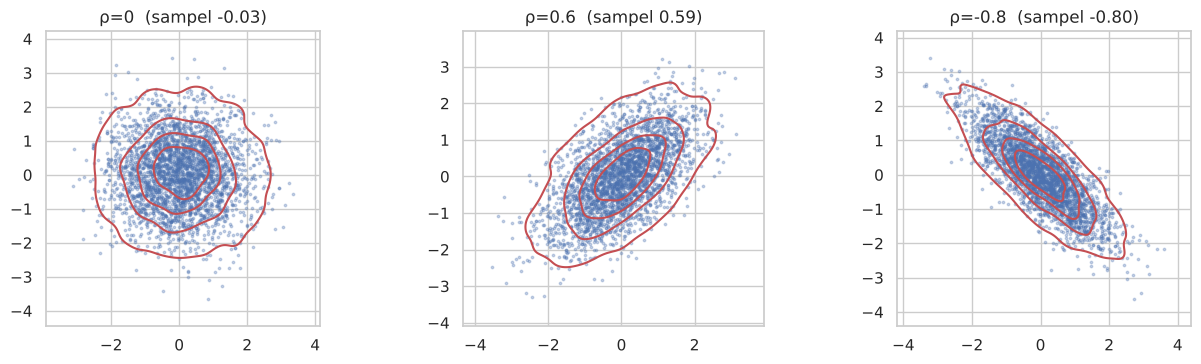

In [13]:
fig,ax=plt.subplots(1,3,figsize=(13,3.8))
for a,r in zip(ax,(0,.6,-.8)):
    S=rng.multivariate_normal([0,0],[[1,r],[r,1]],3000)
    a.scatter(S[:,0],S[:,1],s=3,alpha=.3); sns.kdeplot(x=S[:,0],y=S[:,1],ax=a,levels=5,color="r"); a.set_title(f"ρ={r}  (sampel {np.corrcoef(S.T)[0,1]:.2f})"); a.set_aspect("equal")
plt.tight_layout(); plt.show()

**Interpretasi:** ρ=0 → kontur lingkaran (independen untuk Normal gabungan); ρ>0 miring ke atas; ρ<0 miring ke bawah; makin besar |ρ| makin ramping. Korelasi sampel mendekati parameter.

## 4. Pengembangan Contoh Permasalahan
### Soal 4.1 — Pembaruan Bayes bertahap (Beta posterior)
Peluang konversi θ tidak diketahui; prior Beta(1,1). Data sekuensial dari θ sebenarnya=0,3. Tampilkan posterior setelah 0, 5, 20, 100, 500 pengamatan.

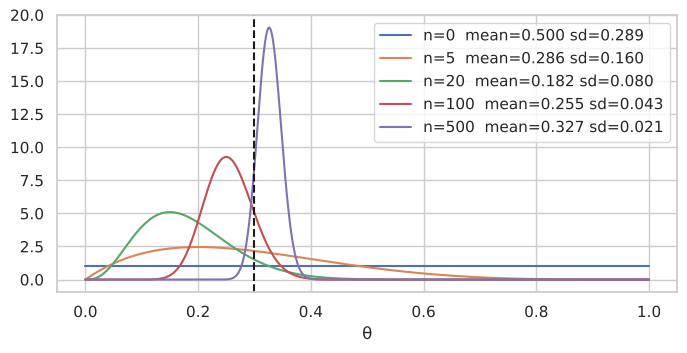

In [14]:
theta=.3; obs=rng.random(500)<theta; x=np.linspace(0,1,500)
fig,ax=plt.subplots(figsize=(8,3.6))
for m in (0,5,20,100,500):
    s=obs[:m].sum(); d=stats.beta(1+s,1+m-s); ax.plot(x,d.pdf(x),label=f"n={m}  mean={d.mean():.3f} sd={d.std():.3f}")
ax.axvline(theta,c="k",ls="--"); ax.legend(); ax.set_xlabel("θ"); plt.show()

**Interpretasi:** Posterior bermula datar (tidak tahu apa-apa), lalu menyempit dan memusat di sekitar θ=0,3 saat data bertambah; simpangan baku turun sebanding 1/√n. Keyakinan diperbarui secara kontinu — inti inferensi Bayes.

### Soal 4.2 — Realisasi proses Poisson dan jeda eksponensial
Gambarkan 5 realisasi kedatangan request (λ=3/dtk selama 5 dtk) dengan `eventplot`, lalu histogram jeda dibanding Eksponensial(3).

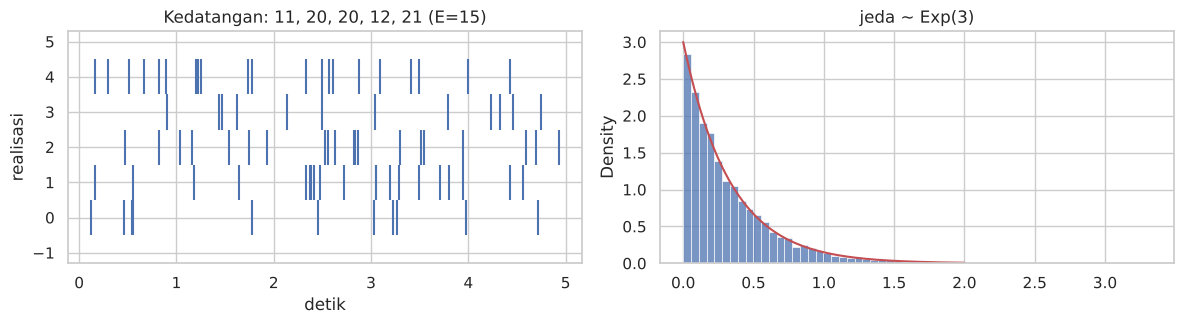

In [15]:
lam,Tm=3,5
times=[np.cumsum(rng.exponential(1/lam,60)) for _ in range(5)]; times=[t[t<Tm] for t in times]
fig,ax=plt.subplots(1,2,figsize=(12,3.4))
ax[0].eventplot(times,colors="C0"); ax[0].set_xlabel("detik"); ax[0].set_ylabel("realisasi"); ax[0].set_title("Kedatangan: "+", ".join(str(len(t)) for t in times)+" (E=15)")
gaps=np.concatenate([np.diff(np.cumsum(rng.exponential(1/lam,2000))) for _ in range(5)])
sns.histplot(gaps,stat="density",bins=60,ax=ax[1]); xx=np.linspace(0,2,200); ax[1].plot(xx,stats.expon(scale=1/lam).pdf(xx),'r'); ax[1].set_title("jeda ~ Exp(3)")
plt.tight_layout(); plt.show()

**Interpretasi:** Kedatangan terlihat bergerombol (ada celah kosong dan kelompok padat) meski laju rata-rata konstan — itulah "keacakan murni". Jumlah kedatangan per realisasi bervariasi di sekitar 15 (Poisson(15)); histogram jeda mengikuti Eksponensial(3).

### Soal 4.3 — Jalan acak (random walk) dan sebaran posisi akhir
200 lintasan jalan acak simetris 400 langkah; posisi akhir ≈ Normal(0, √400=20).

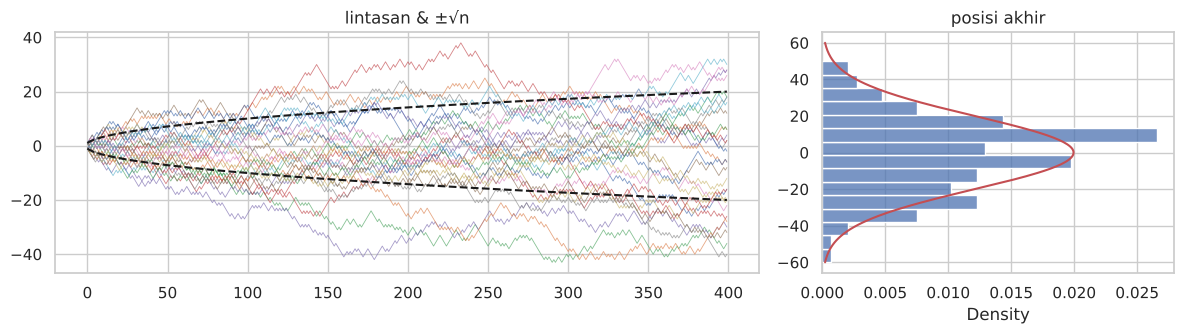

mean akhir=-1.35 sd akhir=20.18 (teori 0 dan 20)


In [16]:
steps=rng.choice([-1,1],(200,400)); path=steps.cumsum(1)
fig,ax=plt.subplots(1,2,figsize=(12,3.5),gridspec_kw={"width_ratios":[2,1]})
ax[0].plot(path[:30].T,lw=.6,alpha=.7); ax[0].plot(np.sqrt(np.arange(1,401)),'k--'); ax[0].plot(-np.sqrt(np.arange(1,401)),'k--'); ax[0].set_title("lintasan & ±√n")
fin=path[:,-1]; sns.histplot(y=fin,ax=ax[1],stat="density",bins=15); yy=np.linspace(-60,60,200); ax[1].plot(stats.norm(0,20).pdf(yy),yy,'r'); ax[1].set_title("posisi akhir")
plt.tight_layout(); plt.show(); print("mean akhir=%.2f sd akhir=%.2f (teori 0 dan 20)"%(fin.mean(),fin.std()))

**Interpretasi:** Simpangan menyebar sebanding √n (garis putus-putus), bukan n. Posisi akhir mendekati N(0,20²) berkat CLT.

## Kesimpulan
1. Visualisasi yang tepat: **bar/stem** untuk PMF, **kurva + area** untuk PDF, **step/ecdf** untuk CDF, **Q–Q plot** untuk uji kecocokan, **heatmap** untuk distribusi gabungan.
2. Grafik memperlihatkan hal yang tidak tampak dari angka ringkasan: ekor berat, korelasi, konvergensi, dan efek prior.
3. Seaborn mempercepat grafik statistik; matplotlib memberi kontrol penuh (pohon peluang, Venn, anotasi).